<a href="https://colab.research.google.com/github/Tanisha291105/AI-program/blob/main/KaranDSV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd

# Load the dataset
file_path = "haberman.csv"

# Read without header initially because the CSV doesn't have column names
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "gilsousa/habermans-survival-data-set",
  file_path,
  pandas_kwargs={"header": None}
)

# Assign descriptive column names according to the dataset documentation:
# 1. Age of patient at time of operation (numerical)
# 2. Patient's year of operation (year - 1900, numerical)
# 3. Number of positive axillary nodes detected (numerical)
# 4. Survival status (class attribute): 1 = survived 5 years or longer, 2 = died within 5 years

print("First 5 records:")
print(df.head())



Using Colab cache for faster access to the 'habermans-survival-data-set' dataset.
First 5 records:
    0   1  2  3
0  30  64  1  1
1  30  62  3  1
2  30  65  0  1
3  31  59  2  1
4  31  65  4  1


In [13]:

print("=== 1. Dataset Overview ===")
print(df.info())

print("\n=== 2. Descriptive Statistics ===")
print(df.describe())

print("\n=== 3. Missing Values Check ===")
print(df.isnull().sum())

=== 1. Dataset Overview ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       306 non-null    int64
 1   1       306 non-null    int64
 2   2       306 non-null    int64
 3   3       306 non-null    int64
dtypes: int64(4)
memory usage: 9.7 KB
None

=== 2. Descriptive Statistics ===
                0           1           2           3
count  306.000000  306.000000  306.000000  306.000000
mean    52.457516   62.852941    4.026144    1.264706
std     10.803452    3.249405    7.189654    0.441899
min     30.000000   58.000000    0.000000    1.000000
25%     44.000000   60.000000    0.000000    1.000000
50%     52.000000   63.000000    1.000000    1.000000
75%     60.750000   65.750000    4.000000    2.000000
max     83.000000   69.000000   52.000000    2.000000

=== 3. Missing Values Check ===
0    0
1    0
2    0
3    0
dtype: int64


### Practical 2: Data Preprocessing

In this step, we will prepare the raw dataset for further analysis and machine learning models. We will:
- Assign descriptive names to the columns.
- Map the target label `Surv_Status` to more intuitive category names.
- Detect and handle duplicate rows.
- Normalize/Scale numerical features to prepare them for potential model training.

In [15]:
# 1. Rename columns
df.columns = ["Age", "Op_Year", "Ax_Nodes", "Surv_Status"]

# 2. Map Survival Status to descriptive categories
# 1 = survived 5 years or longer, 2 = died within 5 years
df['Surv_Status_Label'] = df['Surv_Status'].map({1: 'survived_5yr+', 2: 'died_within_5yr'})

print("Columns successfully renamed and target labels mapped:")
display(df.head())


Columns successfully renamed and target labels mapped:


,Age,Op_Year,Ax_Nodes,Surv_Status,Surv_Status_Label
0,30,64,1,1,survived_5yr+
1,30,62,3,1,survived_5yr+
2,30,65,0,1,survived_5yr+
3,31,59,2,1,survived_5yr+
4,31,65,4,1,survived_5yr+


In [16]:
# 3. Check for and remove duplicate rows
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicates_count}")

if duplicates_count > 0:
    df = df.drop_duplicates()
    print(f"Duplicates removed. New dataset shape: {df.shape}")


Number of duplicate rows found: 17
Duplicates removed. New dataset shape: (289, 5)


In [17]:
from sklearn.preprocessing import StandardScaler

# 4. Feature Scaling (Scaling 'Age' and 'Ax_Nodes')
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[['Age', 'Ax_Nodes']])

# Create a new DataFrame for scaled features to keep the original intact
df_scaled = df.copy()
df_scaled[['Age', 'Ax_Nodes']] = scaled_features

print("Preprocessing Complete! Preprocessed and Scaled Sample:")
display(df_scaled.head())


Preprocessing Complete! Preprocessed and Scaled Sample:


,Age,Op_Year,Ax_Nodes,Surv_Status,Surv_Status_Label
0,-2.065019,64,-0.440537,1,survived_5yr+
1,-2.065019,62,-0.167035,1,survived_5yr+
2,-2.065019,65,-0.577288,1,survived_5yr+
3,-1.972922,59,-0.303786,1,survived_5yr+
4,-1.972922,65,-0.030284,1,survived_5yr+


### Practical 3: Applying Probability Models and Verifying the 3 Axioms of Probability (with Bayes' Theorem)

In this practical, we utilize the processed **Haberman Survival Dataset** to model survival outcomes, verify mathematical axioms of probability, and apply **Bayes' Theorem** to determine conditional medical outcomes.

In [18]:
import numpy as np

# Let's use our cleaned DataFrame 'df'
total_patients = len(df)
print(f"Total number of patients (Sample Space Size |S|): {total_patients}\n")

# --- 1. Define Events ---
# Event A: Patient survived 5 years or longer
# Event B: Patient died within 5 years

count_survived = len(df[df['Surv_Status'] == 1])
count_died = len(df[df['Surv_Status'] == 2])

P_survived = count_survived / total_patients
P_died = count_died / total_patients

print("=== Probability Distribution (Survival Status) ===")
print(f"P(Survived 5yr+) = {P_survived:.4f}")
print(f"P(Died within 5yr) = {P_died:.4f}\n")

# --- 2. Verify the 3 Axioms of Kolmogorov's Probability Theory ---
print("=== Verifying the 3 Axioms of Probability ===")

# Axiom 1: Non-negativity (Probability of any event must be >= 0)
axiom1_survived = P_survived >= 0
axiom1_died = P_died >= 0
print(f"Axiom 1 (Non-negativity): P(Survived) >= 0 is {axiom1_survived}, P(Died) >= 0 is {axiom1_died}")

# Axiom 2: Unit Measure (P(Sample Space S) = 1)
P_S = P_survived + P_died
print(f"Axiom 2 (Unit Measure): P(S) = P(Survived) + P(Died) = {P_S:.4f} (Approximates to 1.0: {np.isclose(P_S, 1.0)})")

# Axiom 3: Additivity of Mutually Exclusive Events
# Since a patient cannot both survive 5yr+ and die within 5yr at the same time, these events are disjoint.
# P(Survived or Died) = P(Survived) + P(Died)
P_union = len(df[(df['Surv_Status'] == 1) | (df['Surv_Status'] == 2)]) / total_patients
P_additivity_sum = P_survived + P_died
print(f"Axiom 3 (Additivity): P(Survived U Died) = {P_union:.4f} | P(Survived) + P(Died) = {P_additivity_sum:.4f} (Equal: {np.isclose(P_union, P_additivity_sum)})")

Total number of patients (Sample Space Size |S|): 289

=== Probability Distribution (Survival Status) ===
P(Survived 5yr+) = 0.7266
P(Died within 5yr) = 0.2734

=== Verifying the 3 Axioms of Probability ===
Axiom 1 (Non-negativity): P(Survived) >= 0 is True, P(Died) >= 0 is True
Axiom 2 (Unit Measure): P(S) = P(Survived) + P(Died) = 1.0000 (Approximates to 1.0: True)
Axiom 3 (Additivity): P(Survived U Died) = 1.0000 | P(Survived) + P(Died) = 1.0000 (Equal: True)


#### Applying Bayes' Theorem
We will evaluate:
$$P(\text{Survived} \mid \text{High Nodes}) = \frac{P(\text{High Nodes} \mid \text{Survived}) \cdot P(\text{Survived})}{P(\text{High Nodes})}$$

Where:
- **Survived** ($S_1$): Patient survived 5 years or longer (`Surv_Status == 1`)
- **High Nodes** ($HN$): Patient had 1 or more positive axillary nodes detected (`Ax_Nodes >= 1`)

In [19]:
# Define events for Bayes' Theorem
# Prior Probabilities
P_S1 = len(df[df['Surv_Status'] == 1]) / total_patients # P(Survived)
P_S2 = len(df[df['Surv_Status'] == 2]) / total_patients # P(Died)

# Condition: High Nodes (HN) defined as having 1 or more positive axillary nodes
df['High_Nodes'] = df['Ax_Nodes'] >= 1
P_HN = len(df[df['High_Nodes'] == True]) / total_patients # Total probability P(HN)

# Likelihoods
# P(HN | S1): Probability of having high nodes given survival
P_HN_given_S1 = len(df[(df['High_Nodes'] == True) & (df['Surv_Status'] == 1)]) / len(df[df['Surv_Status'] == 1])

# P(HN | S2): Probability of having high nodes given death
P_HN_given_S2 = len(df[(df['High_Nodes'] == True) & (df['Surv_Status'] == 2)]) / len(df[df['Surv_Status'] == 2])

# Bayes' Theorem Calculation for Posteriors
# Posterior P(S1 | HN): Probability of survival given high nodes detected
P_S1_given_HN = (P_HN_given_S1 * P_S1) / P_HN

# Posterior P(S2 | HN): Probability of death given high nodes detected
P_S2_given_HN = (P_HN_given_S2 * P_S2) / P_HN

print("=== Bayes' Theorem Calculations ===")
print(f"Prior P(Survived) = {P_S1:.4f}")
print(f"Prior P(Died) = {P_S2:.4f}\n")
print(f"Likelihood P(High Nodes | Survived) = {P_HN_given_S1:.4f}")
print(f"Likelihood P(High Nodes | Died) = {P_HN_given_S2:.4f}\n")
print(f"Total Evidence P(High Nodes) = {P_HN:.4f}\n")
print(f"Posterior P(Survived | High Nodes) = {P_S1_given_HN:.4f}")
print(f"Posterior P(Died | High Nodes) = {P_S2_given_HN:.4f}")
print(f"Sum of posteriors = {P_S1_given_HN + P_S2_given_HN:.4f}")

=== Bayes' Theorem Calculations ===
Prior P(Survived) = 0.7266
Prior P(Died) = 0.2734

Likelihood P(High Nodes | Survived) = 0.5095
Likelihood P(High Nodes | Died) = 0.7722

Total Evidence P(High Nodes) = 0.5813

Posterior P(Survived | High Nodes) = 0.6369
Posterior P(Died | High Nodes) = 0.3631
Sum of posteriors = 1.0000


### Practical 4: Applying Various Sampling Techniques

In this practical, we will treat our cleaned dataset as the **Population** and extract smaller representative **Samples** using different probability sampling methods.

In [24]:
import pandas as pd
import numpy as np

# 1. Define Population and Sample Size
population = df.copy()
N = len(population)
n = 50  # Chosen sample size

print(f"Population Size (N): {N}")
print(f"Target Sample Size (n): {n}\n")

Population Size (N): 289
Target Sample Size (n): 50



In [21]:
# --- Method A: Simple Random Sampling (SRS) ---
# In SRS, every individual in the population has an equal chance of selection.
simple_random_sample = population.sample(n=n, random_state=42)
print("=== Simple Random Sampling ===")
print(f"Sample size: {len(simple_random_sample)}")
display(simple_random_sample.head())

=== Simple Random Sampling ===
Sample size: 50


,Age,Op_Year,Ax_Nodes,Surv_Status,Surv_Status_Label,High_Nodes
47,41,59,8,1,survived_5yr+,True
164,53,60,2,1,survived_5yr+,True
291,70,63,0,1,survived_5yr+,False
44,41,64,0,2,died_within_5yr,False
190,56,65,9,2,died_within_5yr,True


In [22]:
# --- Method B: Systematic Sampling ---
# Select elements at regular intervals (k) from a randomly ordered list starting with a random index.
k = N // n  # Sampling interval
np.random.seed(42)
start_idx = np.random.randint(0, k)  # Random start point
systematic_indices = np.arange(start_idx, N, step=k)[:n]
systematic_sample = population.iloc[systematic_indices]

print("=== Systematic Sampling ===")
print(f"Sampling Interval (k): {k}")
print(f"Start Index: {start_idx}")
print(f"Sample size: {len(systematic_sample)}")
display(systematic_sample.head())

=== Systematic Sampling ===
Sampling Interval (k): 5
Start Index: 3
Sample size: 50


,Age,Op_Year,Ax_Nodes,Surv_Status,Surv_Status_Label,High_Nodes
3,31,59,2,1,survived_5yr+,True
8,34,66,9,2,died_within_5yr,True
13,34,60,0,1,survived_5yr+,False
18,37,60,0,1,survived_5yr+,False
24,38,69,21,2,died_within_5yr,True


In [23]:
# --- Method C: Stratified Sampling ---
# Ensure subgroups (strata) are represented in the same proportion as the population.
# We stratify based on the 'Surv_Status_Label'
population_proportions = population['Surv_Status_Label'].value_counts(normalize=True)
print("=== Stratified Sampling ===")
print("Original Population Proportions:\n", population_proportions, "\n", sep="")

stratified_sample = population.groupby('Surv_Status_Label', group_keys=False).apply(
    lambda x: x.sample(int(np.round(n * len(x) / N)), random_state=42)
)

print(f"Stratified Sample Size: {len(stratified_sample)}")
print("Stratified Sample Proportions:\n", stratified_sample['Surv_Status_Label'].value_counts(normalize=True), sep="")
display(stratified_sample.head())

=== Stratified Sampling ===
Original Population Proportions:
Surv_Status_Label
survived_5yr+      0.726644
died_within_5yr    0.273356
Name: proportion, dtype: float64

Stratified Sample Size: 50
Stratified Sample Proportions:
Surv_Status_Label
survived_5yr+      0.72
died_within_5yr    0.28
Name: proportion, dtype: float64


/tmp/ipykernel_387/416098568.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  stratified_sample = population.groupby('Surv_Status_Label', group_keys=False).apply(


,Age,Op_Year,Ax_Nodes,Surv_Status,Surv_Status_Label,High_Nodes
125,50,64,0,2,died_within_5yr,False
7,34,59,0,2,died_within_5yr,False
96,47,63,23,2,died_within_5yr,True
136,51,59,13,2,died_within_5yr,True
89,46,58,2,2,died_within_5yr,True


### Practical 5: Applying a Regression Model for Prediction

In this practical, we split our preprocessed dataset into train/test splits, fit a Linear Regression model, evaluate its performance, and visualize the actual vs. predicted values with a scatter plot.

In [28]:
from sklearn.model_selection import train_test_split

# --- Step 1: Feature Selection and Data Splitting ---
# Selecting Age and Ax_Nodes as predictors
X = df[['Age', 'Ax_Nodes']]
y = df['Surv_Status']

# Split into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (231, 2)
Testing features shape: (58, 2)


In [29]:
from sklearn.linear_model import LinearRegression

# --- Step 2: Training the Multiple Linear Regression Model ---
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# Generate predictions on the test dataset
y_pred = regressor.predict(X_test)

print("Multiple Linear Regression Model has been trained successfully.")

Multiple Linear Regression Model has been trained successfully.


=== Model Evaluation ===
Mean Squared Error (MSE): 0.2151
R-squared (R2) Score: -0.3111



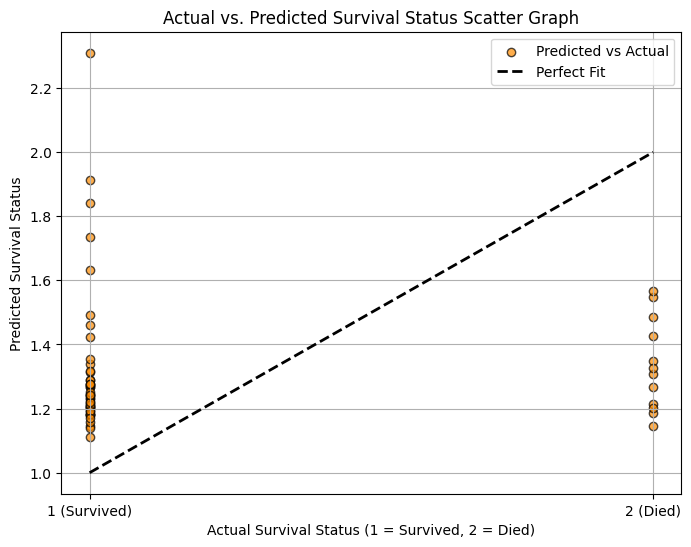

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

# --- Step 3: Model Evaluation & Scatter Graph ---
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== Model Evaluation ===")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}\n")

# Create a scatter plot of Actual vs. Predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='darkorange', alpha=0.7, edgecolors='k', label='Predicted vs Actual')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, label='Perfect Fit')
plt.xlabel('Actual Survival Status (1 = Survived, 2 = Died)')
plt.ylabel('Predicted Survival Status')
plt.title('Actual vs. Predicted Survival Status Scatter Graph')
plt.xticks([1, 2], ['1 (Survived)', '2 (Died)'])
plt.legend()
plt.grid(True)
plt.show()

### Practical 6: Exploring Classification Methods

In this practical, we will train and compare three distinct classification models to predict survival status based on features like `Age` and `Ax_Nodes`:
1. **Decision Tree Classifier**
2. **K-Nearest Neighbors (KNN) Classifier**
3. **Logistic Regression Classifier**

Finally, we will visualize and compare their performance using a bar chart of their accuracy scores.

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# --- Step 1: Decision Tree Classifier ---
# Using the split features X_train, X_test, y_train, y_test from Practical 5
dt_classifier = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_classifier.fit(X_train, y_train)

# Make predictions
dt_predictions = dt_classifier.predict(X_test)

# Calculate accuracy
dt_acc = accuracy_score(y_test, dt_predictions)
print("=== Decision Tree Classifier Performance ===")
print(f"Accuracy: {dt_acc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, dt_predictions))

=== Decision Tree Classifier Performance ===
Accuracy: 0.7586

Classification Report:
              precision    recall  f1-score   support

           1       0.86      0.83      0.84        46
           2       0.43      0.50      0.46        12

    accuracy                           0.76        58
   macro avg       0.65      0.66      0.65        58
weighted avg       0.77      0.76      0.77        58



In [32]:
from sklearn.neighbors import KNeighborsClassifier

# --- Step 2: K-Nearest Neighbors (KNN) Classifier ---
# Standardizing variables is recommended for distance-based algorithms like KNN.
# Since we scaled features in df_scaled, we will use the scaled data split specifically for KNN.
from sklearn.model_selection import train_test_split

X_scaled = df_scaled[['Age', 'Ax_Nodes']]
y_scaled = df_scaled['Surv_Status']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(X_train_s, y_train_s)

# Make predictions
knn_predictions = knn_classifier.predict(X_test_s)

# Calculate accuracy
knn_acc = accuracy_score(y_test_s, knn_predictions)
print("=== K-Nearest Neighbors (KNN) Classifier Performance ===")
print(f"Accuracy: {knn_acc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_s, knn_predictions))

=== K-Nearest Neighbors (KNN) Classifier Performance ===
Accuracy: 0.7241

Classification Report:
              precision    recall  f1-score   support

           1       0.84      0.80      0.82        46
           2       0.36      0.42      0.38        12

    accuracy                           0.72        58
   macro avg       0.60      0.61      0.60        58
weighted avg       0.74      0.72      0.73        58



In [33]:
from sklearn.linear_model import LogisticRegression

# --- Step 3: Logistic Regression Classifier ---
# Using scaled features for stable gradient calculations in Logistic Regression
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_s, y_train_s)

# Make predictions
log_reg_predictions = log_reg.predict(X_test_s)

# Calculate accuracy
log_reg_acc = accuracy_score(y_test_s, log_reg_predictions)
print("=== Logistic Regression Classifier Performance ===")
print(f"Accuracy: {log_reg_acc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_s, log_reg_predictions))

=== Logistic Regression Classifier Performance ===
Accuracy: 0.7414

Classification Report:
              precision    recall  f1-score   support

           1       0.82      0.87      0.84        46
           2       0.33      0.25      0.29        12

    accuracy                           0.74        58
   macro avg       0.57      0.56      0.56        58
weighted avg       0.72      0.74      0.73        58



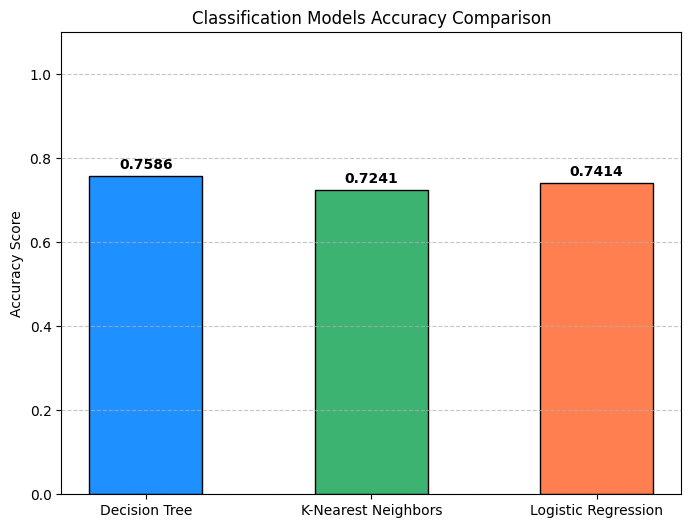

In [34]:
import matplotlib.pyplot as plt

# --- Step 4: Compare Models on a Bar Chart ---
models = ['Decision Tree', 'K-Nearest Neighbors', 'Logistic Regression']
accuracies = [dt_acc, knn_acc, log_reg_acc]

plt.figure(figsize=(8, 6))
colors = ['dodgerblue', 'mediumseagreen', 'coral']
bars = plt.bar(models, accuracies, color=colors, edgecolor='black', width=0.5)

# Formatting the chart
plt.ylim(0, 1.1)
plt.ylabel('Accuracy Score')
plt.title('Classification Models Accuracy Comparison')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Labeling the exact accuracy on top of the bars
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.4f}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # 3 points vertical offset
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, weight='bold')

plt.show()

### Practical 7: Developing Various Charts and Graphs using Visualization Tools

In this practical, we will build multiple visual representations of our dataset's statistics using `matplotlib` and `seaborn`. This includes:
- A **Pie Chart** (Class distribution)
- A **Bar Chart** (Aggregated feature categories)
- A **Scatter Plot** (Relationships between variables)
- A **Line Chart** (Temporal or ordered trends)

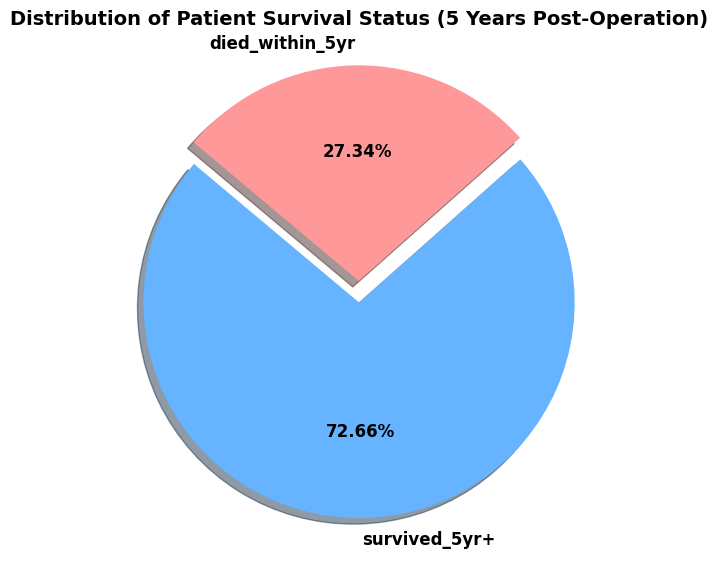

In [35]:
import matplotlib.pyplot as plt

# --- Step 1: Pie Chart (Survival Status Distribution) ---
surval_counts = df['Surv_Status_Label'].value_counts()

plt.figure(figsize=(7, 7))
colors = ['#66b3ff', '#ff9999']
explode = (0, 0.1)  # slightly separate the second slice

plt.pie(surval_counts, explode=explode, labels=surval_counts.index, autopct='%1.2f%%',
        shadow=True, startangle=140, colors=colors, textprops={'fontsize': 12, 'weight': 'bold'})

plt.title("Distribution of Patient Survival Status (5 Years Post-Operation)", fontsize=14, weight='bold')
plt.show()

/tmp/ipykernel_387/2122734476.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_nodes = df_groups.groupby('Age_Group')['Ax_Nodes'].mean().reset_index()
/tmp/ipykernel_387/2122734476.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_nodes, x='Age_Group', y='Ax_Nodes', palette='Blues_d', edgecolor='black')


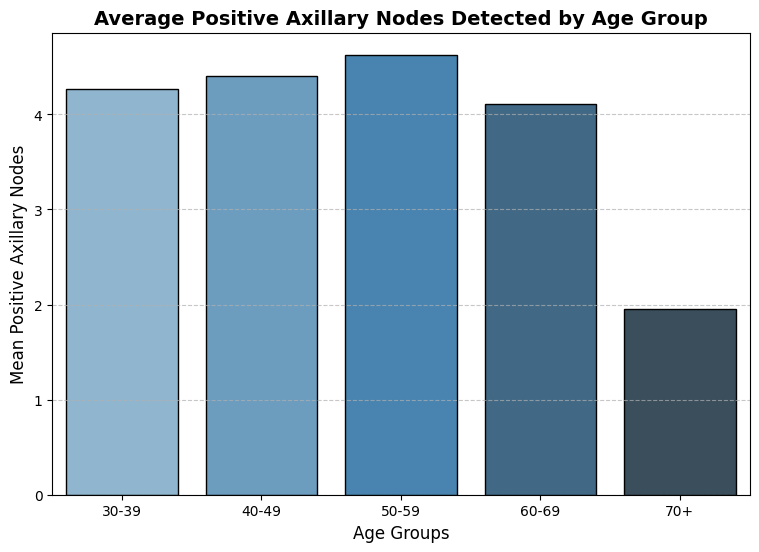

In [36]:
import pandas as pd
import seaborn as sns

# --- Step 2: Bar Chart (Average Positive Axillary Nodes by Age Group) ---
# Create discrete age groups for categorization
bins = [30, 40, 50, 60, 70, 85]
labels = ['30-39', '40-49', '50-59', '60-69', '70+']
df_groups = df.copy()
df_groups['Age_Group'] = pd.cut(df_groups['Age'], bins=bins, labels=labels, right=False)

# Calculate mean nodes per group
avg_nodes = df_groups.groupby('Age_Group')['Ax_Nodes'].mean().reset_index()

plt.figure(figsize=(9, 6))
sns.barplot(data=avg_nodes, x='Age_Group', y='Ax_Nodes', palette='Blues_d', edgecolor='black')

plt.title("Average Positive Axillary Nodes Detected by Age Group", fontsize=14, weight='bold')
plt.xlabel("Age Groups", fontsize=12)
plt.ylabel("Mean Positive Axillary Nodes", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

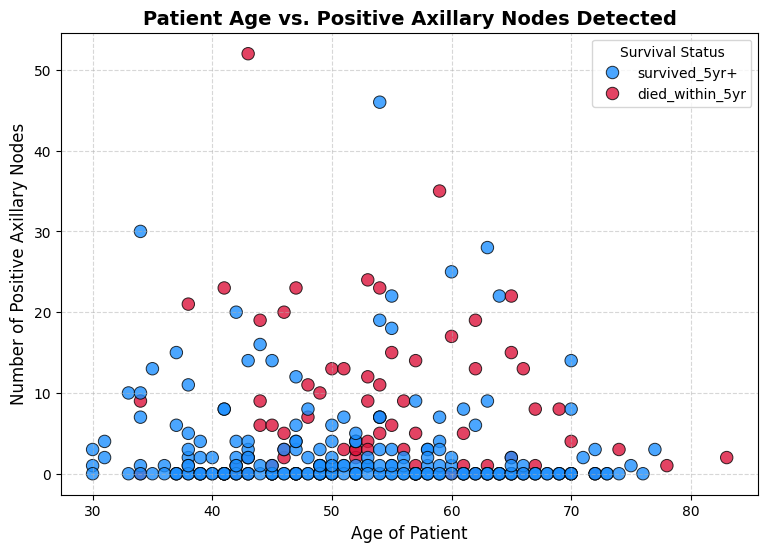

In [37]:
# --- Step 3: Scatter Plot (Age vs. Axillary Nodes) ---
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Age', y='Ax_Nodes', hue='Surv_Status_Label',
                palette={'survived_5yr+': 'dodgerblue', 'died_within_5yr': 'crimson'},
                alpha=0.8, edgecolor='black', s=80)

plt.title("Patient Age vs. Positive Axillary Nodes Detected", fontsize=14, weight='bold')
plt.xlabel("Age of Patient", fontsize=12)
plt.ylabel("Number of Positive Axillary Nodes", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Survival Status")
plt.show()

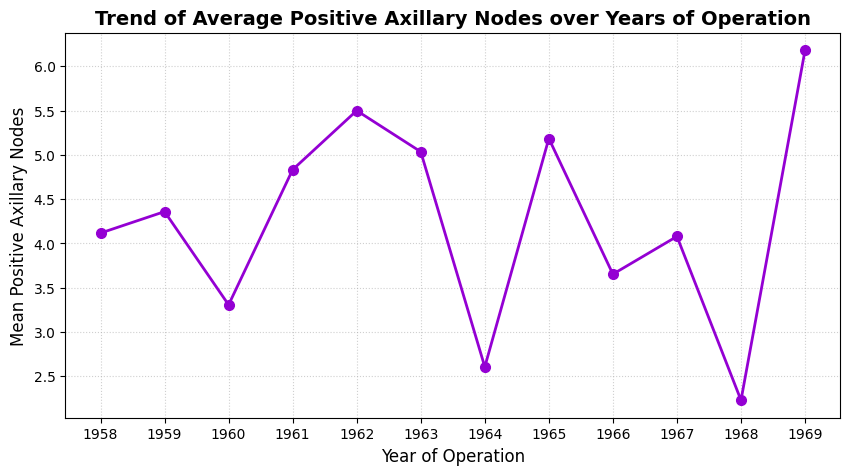

In [38]:
# --- Step 4: Line Chart (Average Positive Nodes over Years of Operation) ---
yearly_nodes = df.groupby('Op_Year')['Ax_Nodes'].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(yearly_nodes['Op_Year'] + 1900, yearly_nodes['Ax_Nodes'], color='darkviolet',
         marker='o', linestyle='-', linewidth=2, markersize=7)

plt.title("Trend of Average Positive Axillary Nodes over Years of Operation", fontsize=14, weight='bold')
plt.xlabel("Year of Operation", fontsize=12)
plt.ylabel("Mean Positive Axillary Nodes", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(yearly_nodes['Op_Year'] + 1900)
plt.show()